<a href="https://colab.research.google.com/github/diandradzil/TUGAS-PDS/blob/main/TUGAS_PDS_MATPLOT_DIANDRA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

DATA PENJUALAN
      nama  jan  feb  mar  apr
0     Andi  100  135   85   75
1     Budi  200  240  185  160
2  Chandra  300  315  285  190
3     Dudi  250  270  230  200
4      Eko  150  195  110  100
5    Fahri   95  130   75   45
6     Gina  125  175  110   70
7   Herman  130  155  100   85
8   Indara  320  374  300  270
9     Joni  200  220  175  155

Informasi Data:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   nama    10 non-null     object
 1   jan     10 non-null     int64 
 2   feb     10 non-null     int64 
 3   mar     10 non-null     int64 
 4   apr     10 non-null     int64 
dtypes: int64(4), object(1)
memory usage: 532.0+ bytes
None


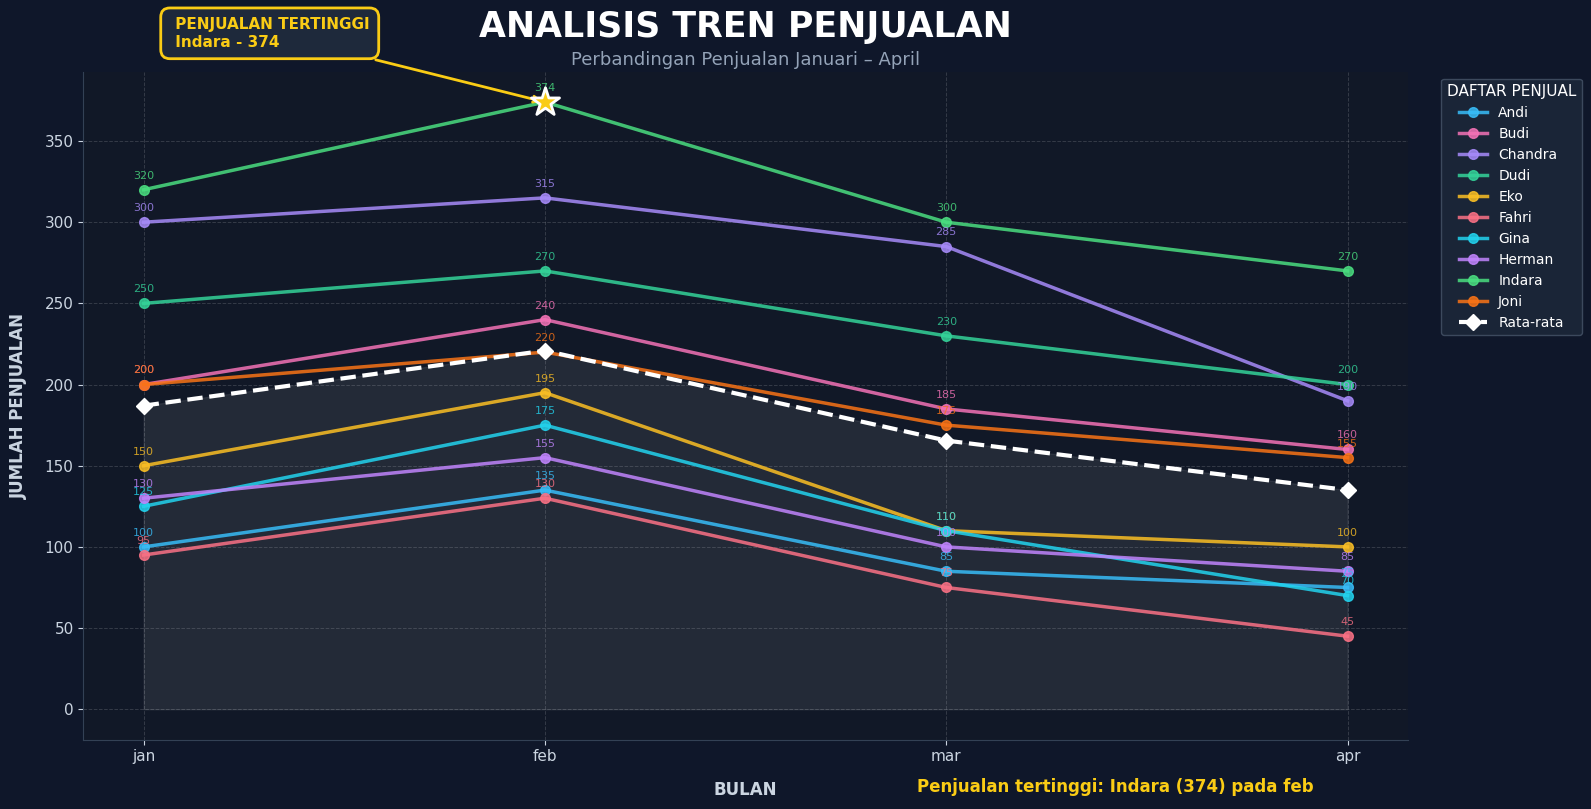


                 HASIL ANALISIS
Bulan dengan penjualan tertinggi : feb
Penjual dengan nilai tertinggi  : Indara
Nilai penjualan tertinggi       : 374

TOTAL PENJUALAN SETIAP BULAN
----------------------------------------
jan        : 1870
feb        : 2209
mar        : 1655
apr        : 1350

RATA-RATA PENJUALAN SETIAP BULAN
----------------------------------------
jan        : 187.00
feb        : 220.90
mar        : 165.50
apr        : 135.00


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ==========================================
# IMPORT DATA
# ==========================================

url = "https://raw.githubusercontent.com/Alam-A99/Pandas_Latih/10ebb3af000e930a44989075733f495d5c2f4be5/penjualan.csv"

df = pd.read_csv(url)

print("DATA PENJUALAN")
print(df)

print("\nInformasi Data:")
print(df.info())


# ==========================================
# EDIT DATA
# ==========================================

bulan = df.columns[1:]
nama = df.iloc[:, 0]
penjualan = df.iloc[:, 1:]

data = penjualan.to_numpy()

# Total penjualan setiap bulan
total_bulanan = np.sum(data, axis=0)

# Rata-rata penjualan setiap bulan
rata_bulanan = np.mean(data, axis=0)

# Nilai maksimum
nilai_maks = np.max(data)

# Posisi nilai maksimum
posisi_maks = np.unravel_index(
    np.argmax(data),
    data.shape
)

nama_maks = nama.iloc[posisi_maks[0]]
bulan_maks = bulan[posisi_maks[1]]


# ==========================================
# DESAIN GRAFIK
# ==========================================

plt.style.use("dark_background")

fig, ax = plt.subplots(
    figsize=(16, 9)
)

# Background
fig.patch.set_facecolor("#0f172a")
ax.set_facecolor("#111827")


# ==========================================
# WARNA SETIAP PENJUAL
# ==========================================

warna = [
    "#38bdf8",
    "#f472b6",
    "#a78bfa",
    "#34d399",
    "#fbbf24",
    "#fb7185",
    "#22d3ee",
    "#c084fc",
    "#4ade80",
    "#f97316"
]


# ==========================================
# DATA SETIAP PENJUAL
# ==========================================

for i in range(len(nama)):

    ax.plot(
        bulan,
        penjualan.iloc[i],
        marker="o",
        markersize=7,
        linewidth=2.5,
        color=warna[i],
        alpha=0.85,
        label=nama.iloc[i]
    )

    # Label nilai pada setiap titik
    for j in range(len(bulan)):

        ax.annotate(
            str(penjualan.iloc[i, j]),
            (
                bulan[j],
                penjualan.iloc[i, j]
            ),
            textcoords="offset points",
            xytext=(0, 8),
            ha="center",
            fontsize=8,
            color=warna[i],
            alpha=0.8
        )


# ==========================================
# GARIS RATA-RATA
# ==========================================

ax.plot(
    bulan,
    rata_bulanan,
    color="white",
    linestyle="--",
    linewidth=3,
    marker="D",
    markersize=8,
    label="Rata-rata",
    zorder=5
)


# ==========================================
# AREA RATA-RATA
# ==========================================

ax.fill_between(
    bulan,
    rata_bulanan,
    alpha=0.08,
    color="white"
)


# ==========================================
# HIGHLIGHT NILAI TERTINGGI
# ==========================================

ax.scatter(
    bulan_maks,
    nilai_maks,
    s=450,
    marker="*",
    color="#facc15",
    edgecolors="white",
    linewidth=2,
    zorder=10
)


# ==========================================
# ANOTASI NILAI TERTINGGI
# ==========================================

ax.annotate(
    f" PENJUALAN TERTINGGI\n {nama_maks} - {nilai_maks}",
    xy=(bulan_maks, nilai_maks),
    xytext=(-270, 40),
    textcoords="offset points",
    fontsize=11,
    fontweight="bold",
    color="#facc15",
    bbox=dict(
        boxstyle="round,pad=0.6",
        facecolor="#1e293b",
        edgecolor="#facc15",
        linewidth=2
    ),
    arrowprops=dict(
        arrowstyle="->",
        color="#facc15",
        linewidth=2
    )
)


# ==========================================
# JUDUL
# ==========================================

ax.set_title(
    "ANALISIS TREN PENJUALAN",
    fontsize=25,
    fontweight="bold",
    color="white",
    pad=25
)

ax.text(
    0.5,
    1.01,
    "Perbandingan Penjualan Januari – April",
    transform=ax.transAxes,
    ha="center",
    fontsize=13,
    color="#94a3b8"
)


# ==========================================
# LABEL AXIS
# ==========================================

ax.set_xlabel(
    "BULAN",
    fontsize=12,
    fontweight="bold",
    color="#cbd5e1",
    labelpad=12
)

ax.set_ylabel(
    "JUMLAH PENJUALAN",
    fontsize=12,
    fontweight="bold",
    color="#cbd5e1",
    labelpad=12
)


# ==========================================
# GRID
# ==========================================

ax.grid(
    True,
    linestyle="--",
    linewidth=0.7,
    alpha=0.15
)


# ==========================================
# HILANGKAN BORDER
# ==========================================

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_color("#334155")
ax.spines["bottom"].set_color("#334155")


# ==========================================
# LEGEND
# ==========================================

legend = ax.legend(
    title="DAFTAR PENJUAL",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    frameon=True,
    fontsize=10,
    title_fontsize=11
)

legend.get_frame().set_facecolor("#1e293b")
legend.get_frame().set_edgecolor("#475569")


# ==========================================
# TICK
# ==========================================

ax.tick_params(
    colors="#cbd5e1",
    labelsize=11
)


# ==========================================
# INFORMASI RINGKAS DI BAWAH
# ==========================================

fig.text(
    0.7,
    0.025,
    f"Penjualan tertinggi: {nama_maks} ({nilai_maks}) pada {bulan_maks}",
    ha="center",
    fontsize=12,
    fontweight="bold",
    color="#facc15"
)


# ==========================================
# LAYOUT
# ==========================================

plt.tight_layout(
    rect=[0, 0, 1, 0.91]
)

plt.show()


# ==========================================
# ANALISIS DATA
# ==========================================

print("\n" + "=" * 55)
print("                 HASIL ANALISIS")
print("=" * 55)

print(
    f"Bulan dengan penjualan tertinggi : {bulan_maks}"
)

print(
    f"Penjual dengan nilai tertinggi  : {nama_maks}"
)

print(
    f"Nilai penjualan tertinggi       : {nilai_maks}"
)


print("\nTOTAL PENJUALAN SETIAP BULAN")
print("-" * 40)

for i in range(len(bulan)):

    print(
        f"{bulan[i]:<10} : {total_bulanan[i]}"
    )


print("\nRATA-RATA PENJUALAN SETIAP BULAN")
print("-" * 40)

for i in range(len(bulan)):

    print(
        f"{bulan[i]:<10} : {rata_bulanan[i]:.2f}"
    )

print("=" * 55)



        ANALISIS DATA FISKAL DAN PEMBANGUNAN DAERAH

5 DATA PERTAMA:
              Kota  Tahun  DBH_PAJAK  DBH_SDA  DBH_Lainnya  DAU_Grant  \
0  Kota Banda Aceh   2014      77.91    49.42        26.00      96.98   
1  Kota Banda Aceh   2015      54.88    37.29        35.35     112.77   
2  Kota Banda Aceh   2016      78.91    27.08        39.83     107.56   
3  Kota Banda Aceh   2017      72.77    26.01        46.46     109.93   
4  Kota Banda Aceh   2018      93.06    82.81        31.70     127.89   

   DAU_Earmark  DAK_Fisik  DAK_Nonfisik     PAD  ...  bm_lingkungan  \
0        47.59      83.94         72.02  153.66  ...         175.78   
1        59.88      74.74         52.84  119.84  ...          98.47   
2        52.78      96.58         97.41  179.24  ...         264.70   
3        80.91      63.84         73.98  150.55  ...         219.24   
4        60.87      77.19         80.88  148.09  ...         259.48   

   bm_ekonomi  bm_infrastruktur  bm_pariwisata  bm_perlindungan

NameError: name 'ipm_awal' is not defined

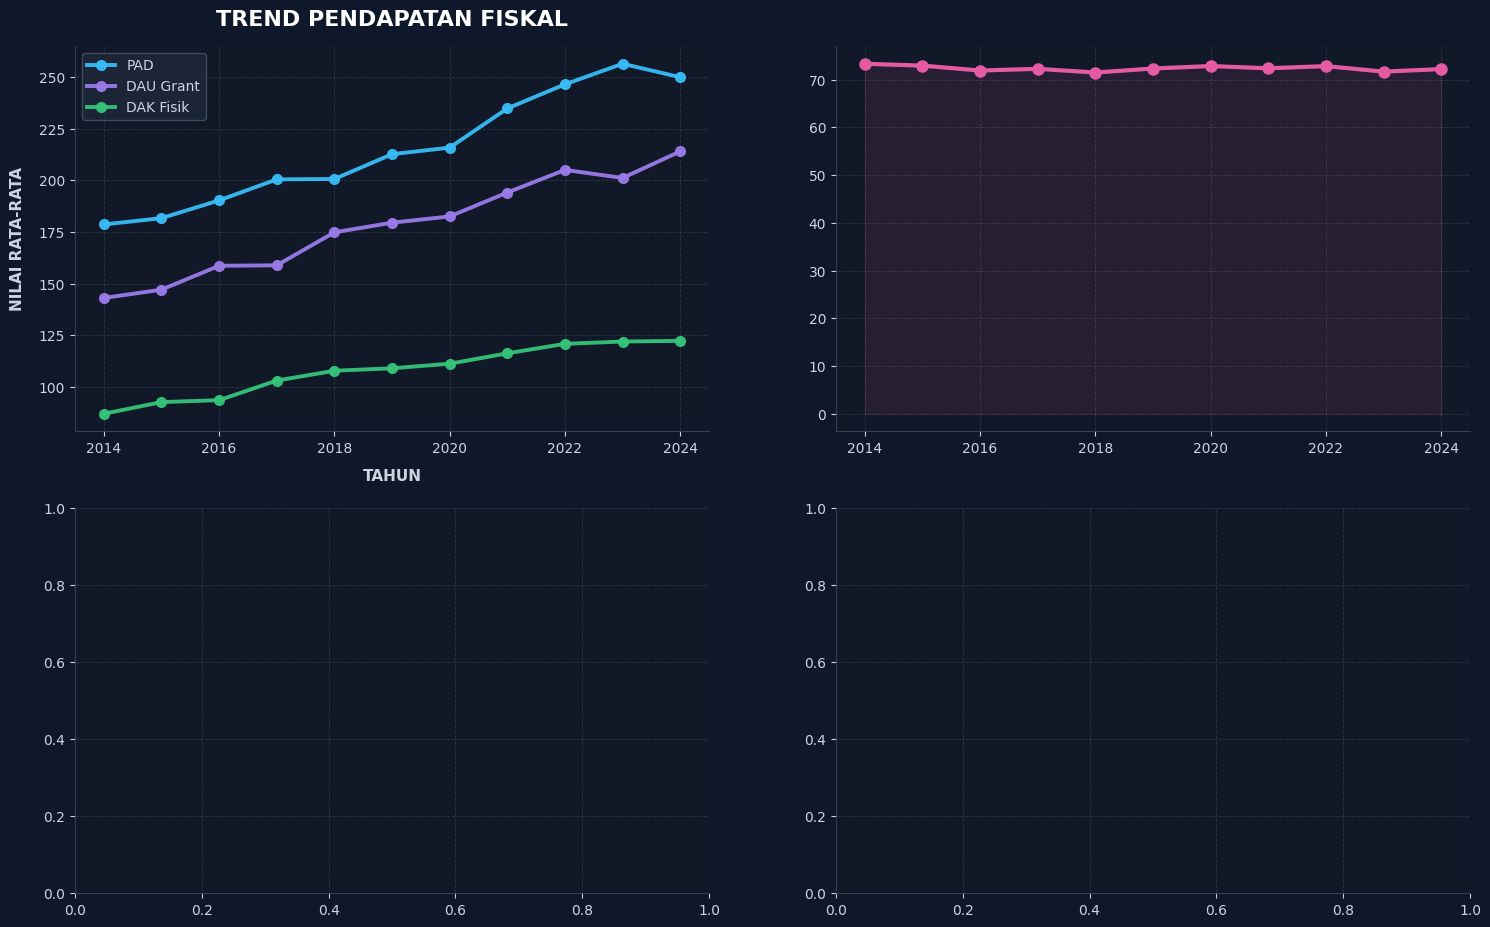

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


# =========================================================
# 1. IMPORT DATA
# =========================================================

url = "https://raw.githubusercontent.com/Alam-A99/DATAAKSI/refs/heads/main/dataset_fiskal_97_hipoFull.csv"

df = pd.read_csv(url)

print("=" * 70)
print("\n\n        ANALISIS DATA FISKAL DAN PEMBANGUNAN DAERAH")
print("=" * 70)

print("\n5 DATA PERTAMA:")
print(df.head())

print("\nINFORMASI DATA:")
print(df.info())

print("\nJUMLAH KOTA :", df["Kota"].nunique())
print("TAHUN       :", df["Tahun"].min(), "-", df["Tahun"].max())
print("JUMLAH DATA :", len(df))


# =========================================================
# 2. PEMBERSIHAN DATA
# =========================================================

# Mengubah kolom tahun menjadi integer
df["Tahun"] = df["Tahun"].astype(int)

# Mengambil kolom numerik
kolom_numerik = df.select_dtypes(include=np.number).columns

# Mengubah data menjadi numerik
df[kolom_numerik] = df[kolom_numerik].apply(
    pd.to_numeric,
    errors="coerce"
)


# =========================================================
# 3. RATA-RATA NASIONAL PER TAHUN
# =========================================================

tahunan = df.groupby("Tahun").mean(numeric_only=True)


tahun = tahunan.index.to_numpy()


# =========================================================
# 4. WARNA PASTEL
# =========================================================

biru = "#74B9FF"
pink = "#FF9FCB"
ungu = "#A78BFA"
hijau = "#70D6BE"
kuning = "#FFD166"
orange = "#FFB36B"
merah = "#FF8FA3"
abu = "#6C7293"

background = "#F8F7FF"


# =========================================================
# TEMA GRAFIK - DARK NAVY
# =========================================================

plt.style.use("dark_background")

fig, axes = plt.subplots(
    2,
    2,
    figsize=(18, 11)
)

# Background utama
fig.patch.set_facecolor("#0F172A")

# Background setiap grafik
for ax in axes.flat:
    ax.set_facecolor("#111827")

    # Grid
    ax.grid(
        True,
        linestyle="--",
        linewidth=0.7,
        alpha=0.18,
        color="#94A3B8"
    )

    # Border
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    ax.spines["left"].set_color("#334155")
    ax.spines["bottom"].set_color("#334155")

    # Tulisan axis
    ax.tick_params(
        colors="#CBD5E1",
        labelsize=10
    )


# =========================================================
# PALET WARNA SEPERTI GAMBAR
# =========================================================

biru = "#38BDF8"
pink = "#E45BA3"
ungu = "#9B7BEA"
hijau = "#35C47A"
kuning = "#FBBF24"
orange = "#F97316"
merah = "#F06A7A"
cyan = "#22C1DD"
lavender = "#B36DE8"
hijau_muda = "#4ADE80"

putih = "#FFFFFF"
abu = "#CBD5E1"
abu_muda = "#94A3B8"
background = "#0F172A"


# =========================================================
# GRAFIK 1
# TREN PENDAPATAN FISKAL
# =========================================================

ax1 = axes[0, 0]

ax1.plot(
    tahun,
    tahunan["PAD"],
    marker="o",
    markersize=7,
    linewidth=2.8,
    color=biru,
    alpha=0.95,
    label="PAD"
)

ax1.plot(
    tahun,
    tahunan["DAU_Grant"],
    marker="o",
    markersize=7,
    linewidth=2.8,
    color=ungu,
    alpha=0.95,
    label="DAU Grant"
)

ax1.plot(
    tahun,
    tahunan["DAK_Fisik"],
    marker="o",
    markersize=7,
    linewidth=2.8,
    color=hijau,
    alpha=0.95,
    label="DAK Fisik"
)

ax1.set_title(
    "TREND PENDAPATAN FISKAL",
    fontsize=16,
    fontweight="bold",
    color=putih,
    pad=15
)

ax1.set_xlabel(
    "TAHUN",
    fontsize=11,
    fontweight="bold",
    color=abu,
    labelpad=10
)

ax1.set_ylabel(
    "NILAI RATA-RATA",
    fontsize=11,
    fontweight="bold",
    color=abu,
    labelpad=10
)

ax1.legend(
    frameon=True,
    facecolor="#1E293B",
    edgecolor="#475569",
    labelcolor=abu
)


# =========================================================
# GRAFIK 2
# TREN IPM
# =========================================================

ax2 = axes[0, 1]

ax2.plot(
    tahun,
    tahunan["IPM"],
    marker="o",
    markersize=8,
    linewidth=3,
    color=pink,
    label="IPM"
)

ax2.fill_between(
    tahun,
    tahunan["IPM"],
    alpha=0.10,
    color=pink
)

# Titik awal
ax2.scatter(
    tahun[0],
    ipm_awal,
    s=100,
    color=biru,
    edgecolors=putih,
    linewidth=1.5,
    zorder=5
)

# Titik akhir
ax2.scatter(
    tahun[-1],
    ipm_akhir,
    s=100,
    color=kuning,
    edgecolors=putih,
    linewidth=1.5,
    zorder=5
)

ax2.set_title(
    "PERKEMBANGAN INDEKS PEMBANGUNAN MANUSIA",
    fontsize=16,
    fontweight="bold",
    color=putih,
    pad=15
)

ax2.set_xlabel(
    "TAHUN",
    fontsize=11,
    fontweight="bold",
    color=abu
)

ax2.set_ylabel(
    "IPM",
    fontsize=11,
    fontweight="bold",
    color=abu
)


# =========================================================
# GRAFIK 3
# KEMISKINAN DAN PENGANGGURAN
# =========================================================

ax3 = axes[1, 0]

ax3.plot(
    tahun,
    tahunan["KEMISKINAN"],
    marker="o",
    markersize=7,
    linewidth=2.8,
    color=orange,
    label="Kemiskinan"
)

ax3.plot(
    tahun,
    tahunan["PENGANGGURAN"],
    marker="o",
    markersize=7,
    linewidth=2.8,
    color=merah,
    label="Pengangguran"
)

ax3.set_title(
    "TREN KEMISKINAN DAN PENGANGGURAN",
    fontsize=16,
    fontweight="bold",
    color=putih,
    pad=15
)

ax3.set_xlabel(
    "TAHUN",
    fontsize=11,
    fontweight="bold",
    color=abu
)

ax3.set_ylabel(
    "NILAI RATA-RATA",
    fontsize=11,
    fontweight="bold",
    color=abu
)

ax3.legend(
    frameon=True,
    facecolor="#1E293B",
    edgecolor="#475569",
    labelcolor=abu
)


# =========================================================
# GRAFIK 4
# HUBUNGAN PAD DAN IPM
# =========================================================

ax4 = axes[1, 1]

ax4.scatter(
    x_clean,
    y_clean,
    s=40,
    alpha=0.55,
    color=cyan,
    edgecolors="none"
)

# Garis trend
ax4.plot(
    x_garis,
    y_garis,
    color=kuning,
    linewidth=3,
    linestyle="--",
    label="Garis Tren"
)

ax4.set_title(
    "HUBUNGAN PAD DENGAN IPM",
    fontsize=16,
    fontweight="bold",
    color=putih,
    pad=15
)

ax4.set_xlabel(
    "PAD",
    fontsize=11,
    fontweight="bold",
    color=abu
)

ax4.set_ylabel(
    "IPM",
    fontsize=11,
    fontweight="bold",
    color=abu
)

ax4.legend(
    frameon=True,
    facecolor="#1E293B",
    edgecolor="#475569",
    labelcolor=abu
)


# =========================================================
# JUDUL UTAMA
# =========================================================

fig.suptitle(
    "ANALISIS FISKAL DAN PEMBANGUNAN DAERAH",
    fontsize=22,
    fontweight="bold",
    color=putih,
    y=0.98
)

fig.text(
    0.5,
    0.94,
    "Analisis Data Fiskal dan Indikator Pembangunan 2014–2024",
    ha="center",
    fontsize=11,
    color=abu_muda
)


# =========================================================
# LAYOUT
# =========================================================

plt.tight_layout(
    rect=[0, 0.03, 1, 0.93]
)

plt.show()


# =========================================================
# 8. ANALISIS MENGGUNAKAN NUMPY
# =========================================================

# Perubahan IPM
perubahan_ipm = ipm_akhir - ipm_awal

persen_ipm = (
    perubahan_ipm / ipm_awal
) * 100


# Rata-rata PAD
rata_pad = np.mean(df["PAD"])

# Rata-rata kemiskinan
rata_kemiskinan = np.mean(
    df["KEMISKINAN"]
)

# Rata-rata pengangguran
rata_pengangguran = np.mean(
    df["PENGANGGURAN"]
)


# =========================================================
# 9. KORELASI PAD DAN IPM
# =========================================================

korelasi_pad_ipm = np.corrcoef(
    x_clean,
    y_clean
)[0, 1]


# =========================================================
# 10. NILAI TERTINGGI DAN TERENDAH
# =========================================================

tahun_ipm_tertinggi = tahunan["IPM"].idxmax()
nilai_ipm_tertinggi = tahunan["IPM"].max()

tahun_ipm_terendah = tahunan["IPM"].idxmin()
nilai_ipm_terendah = tahunan["IPM"].min()


tahun_pad_tertinggi = tahunan["PAD"].idxmax()
nilai_pad_tertinggi = tahunan["PAD"].max()


tahun_kemiskinan_tertinggi = (
    tahunan["KEMISKINAN"].idxmax()
)

nilai_kemiskinan_tertinggi = (
    tahunan["KEMISKINAN"].max()
)


tahun_pengangguran_tertinggi = (
    tahunan["PENGANGGURAN"].idxmax()
)

nilai_pengangguran_tertinggi = (
    tahunan["PENGANGGURAN"].max()
)


# =========================================================
# 11. HASIL ANALISIS
# =========================================================

print("\n")
print("=" * 70)
print("                 HASIL ANALISIS DATA")
print("=" * 70)


print("\n1. PERKEMBANGAN IPM")
print("-" * 50)

print(
    f"IPM rata-rata tahun {tahun[0]} : "
    f"{ipm_awal:.2f}"
)

print(
    f"IPM rata-rata tahun {tahun[-1]} : "
    f"{ipm_akhir:.2f}"
)

print(
    f"Perubahan IPM                 : "
    f"{perubahan_ipm:.2f}"
)

print(
    f"Persentase perubahan          : "
    f"{persen_ipm:.2f}%"
)

print(
    f"IPM tertinggi terjadi pada    : "
    f"{tahun_ipm_tertinggi} "
    f"({nilai_ipm_tertinggi:.2f})"
)

print(
    f"IPM terendah terjadi pada     : "
    f"{tahun_ipm_terendah} "
    f"({nilai_ipm_terendah:.2f})"
)


print("\n2. KONDISI FISKAL")
print("-" * 50)

print(
    f"Rata-rata PAD seluruh data    : "
    f"{rata_pad:.2f}"
)

print(
    f"PAD rata-rata tertinggi       : "
    f"{tahun_pad_tertinggi} "
    f"({nilai_pad_tertinggi:.2f})"
)


print("\n3. KONDISI SOSIAL")
print("-" * 50)

print(
    f"Rata-rata kemiskinan          : "
    f"{rata_kemiskinan:.2f}"
)

print(
    f"Rata-rata pengangguran        : "
    f"{rata_pengangguran:.2f}"
)

print(
    f"Kemiskinan tertinggi          : "
    f"{tahun_kemiskinan_tertinggi} "
    f"({nilai_kemiskinan_tertinggi:.2f})"
)

print(
    f"Pengangguran tertinggi        : "
    f"{tahun_pengangguran_tertinggi} "
    f"({nilai_pengangguran_tertinggi:.2f})"
)


print("\n4. HUBUNGAN PAD DAN IPM")
print("-" * 50)

print(
    f"Koefisien korelasi PAD-IPM   : "
    f"{korelasi_pad_ipm:.3f}"
)


# =========================================================
# 12. INTERPRETASI OTOMATIS
# =========================================================

print("\n")
print("=" * 70)
print("                     INTERPRETASI")
print("=" * 70)


# Interpretasi IPM

if perubahan_ipm > 0:
    print(
        f"\n• IPM menunjukkan kecenderungan meningkat "
        f"dari {ipm_awal:.2f} pada {tahun[0]} "
        f"menjadi {ipm_akhir:.2f} pada {tahun[-1]}. "
        f"Hal ini menunjukkan adanya peningkatan rata-rata "
        f"indikator pembangunan manusia selama periode pengamatan."
    )
else:
    print(
        f"\n• IPM mengalami penurunan rata-rata "
        f"dari {ipm_awal:.2f} menjadi {ipm_akhir:.2f}."
    )


# Interpretasi korelasi

if korelasi_pad_ipm > 0.7:

    print(
        "\n• Hubungan PAD dan IPM memiliki korelasi positif "
        "yang relatif kuat. Dalam data ini, daerah dengan "
        "PAD yang lebih tinggi cenderung memiliki nilai IPM "
        "yang lebih tinggi."
    )

elif korelasi_pad_ipm > 0.3:

    print(
        "\n• Hubungan PAD dan IPM menunjukkan korelasi positif "
        "tingkat sedang. Artinya, peningkatan PAD dalam "
        "data cenderung berjalan bersama dengan nilai IPM "
        "yang lebih tinggi."
    )

elif korelasi_pad_ipm > -0.3:

    print(
        "\n• Hubungan PAD dan IPM relatif lemah. "
        "Perubahan PAD tidak menunjukkan hubungan linear "
        "yang kuat dengan IPM dalam dataset ini."
    )

else:

    print(
        "\n• Hubungan PAD dan IPM menunjukkan korelasi negatif. "
        "Dalam dataset ini, nilai PAD yang lebih tinggi "
        "cenderung berkaitan dengan nilai IPM yang lebih rendah."
    )


# Interpretasi kemiskinan

print(
    f"\n• Rata-rata kemiskinan seluruh observasi adalah "
    f"{rata_kemiskinan:.2f}, sedangkan rata-rata "
    f"pengangguran adalah {rata_pengangguran:.2f}."
)


# Interpretasi fiskal

print(
    f"\n• Perkembangan PAD, DAU Grant, dan DAK Fisik "
    f"dapat digunakan untuk melihat perubahan kapasitas "
    f"dan dukungan fiskal daerah dari waktu ke waktu."
)


print(
    "\n• Hubungan statistik yang ditampilkan pada grafik "
    "tidak secara otomatis menunjukkan hubungan sebab-akibat. "
    "Korelasi hanya menunjukkan pola hubungan dalam data."
)


print("\n" + "=" * 70)
print("                 ANALISIS SELESAI")
print("=" * 70)